In [1]:
#!pip install botorch
#!pip install pyDOE
#!pip install openpyxl
#!pip install smt
#!pip install scikit-optimize

In [2]:
# Support for math
import numpy as np
import math

# Plotting tools
from matplotlib import pyplot as plt
import matplotlib

import warnings
warnings.filterwarnings('ignore')

#File Tools for local
import pandas as pd

#Sampling
from pyDOE import lhs



In [3]:
import torch
from botorch.models import SingleTaskGP, ModelListGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.models.transforms.outcome import Standardize
from botorch.utils.sampling import draw_sobol_samples
from botorch.fit import fit_gpytorch_model
from botorch.acquisition.multi_objective import qExpectedHypervolumeImprovement
from botorch.optim import optimize_acqf
from botorch.utils.sampling import draw_sobol_samples
from botorch.utils.multi_objective import pareto
from botorch.utils.multi_objective.box_decompositions.non_dominated import FastNondominatedPartitioning
from gpytorch.mlls import ExactMarginalLogLikelihood
from torch.quasirandom import SobolEngine
import matplotlib.pyplot as plt
from botorch.models.deterministic import PosteriorMeanModel


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32
dim = 3
N = 12
MC_SAMPLES = 128
NUM_RESTARTS = 10
RAW_SAMPLES = 512

BATCH_SIZE = 1
iteration_number = 20
#bounds of the inputs
bounds = torch.stack([torch.zeros(dim), torch.ones(dim)*300]).to(device=device, dtype=dtype)
refi = torch.tensor([10., 10., 10.], device=device, dtype=dtype)

#Generate points

In [5]:
from pyDOE import lhs
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # Step 1: Generate Latin Hypercube Samples
    seed
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

sampled_colors = latin_hypercube_sum_constraint(12, 3, 300,np.random.seed(2))//1
sampled_colors.transpose()

array([[ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
         15.],
       [ 39.,  76.,  78., 122., 128., 124., 153.,  37., 125., 100.,  39.,
         69.],
       [177.,  57., 116., 150.,  62.,  91., 114.,  47.,  59.,  59.,  46.,
        214.]])

In [6]:
test_colors = latin_hypercube_sum_constraint(8, 3, 300,np.random.seed(1))
test_colors.T

array([[ 63.71345478,  65.37859309, 112.58538392, 146.23075328,
        104.62865987, 209.01047487,  70.06274528,   7.63689549],
       [201.06725529, 132.82966093,  49.91098934, 109.7745757 ,
        114.62358182,  24.20451755, 132.23085965,  36.27034483],
       [ 35.21928992, 101.79174598, 137.50362674,  43.99467102,
         80.74775831,  66.78500758,  97.70639506, 256.09275968]])

#import data

In [7]:
# Path
xls = pd.read_excel("/Users/clarat/Documents/Sun Lab/Mara_colors/mara_color_data/02_23_Random_Color_Increment.xlsx",sheet_name=["End point","RGB"],engine='openpyxl')

df = xls.get('End point')
df_RGB = xls.get('RGB')

df.head()

,Well\nRow,Well\nCol,Content,Concentration,Raw Data (Abs Spectrum),Raw Data (Abs Spectrum).1,Raw Data (Abs Spectrum).2,Raw Data (Abs Spectrum).3,Raw Data (Abs Spectrum).4,Raw Data (Abs Spectrum).5,...,Raw Data (Abs Spectrum).141,Raw Data (Abs Spectrum).142,Raw Data (Abs Spectrum).143,Raw Data (Abs Spectrum).144,Raw Data (Abs Spectrum).145,Raw Data (Abs Spectrum).146,Raw Data (Abs Spectrum).147,Raw Data (Abs Spectrum).148,Raw Data (Abs Spectrum).149,Raw Data (Abs Spectrum).150
0,NaN,NaN,Wavelength [nm],NaN,400.000,402.000,404.000,406.000,408.000,410.000,...,682.000,684.000,686.000,688.000,690.000,692.000,694.000,696.000,698.000,700.000
1,D,1.0,Sample X37,74626.252,1.363,1.391,1.409,1.438,1.459,1.474,...,0.043,0.042,0.040,0.038,0.035,0.034,0.033,0.031,0.030,0.030
2,D,2.0,Sample X38,25529.573,0.627,0.648,0.663,0.677,0.689,0.694,...,0.066,0.061,0.056,0.051,0.047,0.043,0.041,0.037,0.036,0.035
3,D,3.0,Sample X39,42472.278,0.997,1.023,1.044,1.065,1.080,1.093,...,0.067,0.061,0.057,0.053,0.050,0.047,0.044,0.041,0.040,0.038
4,D,4.0,Sample X40,32500.649,1.461,1.497,1.528,1.560,1.574,1.584,...,0.277,0.267,0.260,0.253,0.247,0.243,0.239,0.236,0.234,0.231


Inputs

In [8]:
vol_red  = sampled_colors[:,0]
vol_blue = sampled_colors[:,1]
vol_yelo = sampled_colors[:,2]
vol_red

array([ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
        15.])

Outputs

In [9]:
vol_mag  = sampled_colors[:,0]
vol_cya = sampled_colors[:,1]
vol_yelo = sampled_colors[:,2]
vol_mag

array([ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
        15.])

In [10]:
#data selection
#Example spectra
def spectra_selection(id):
  xvals = df.iloc[0, 4:]
  yvals = df.iloc[id,4:]
  return [xvals,yvals]

def interval_selection(id,min,max):
  min = np.where(df==min)[1][0]
  max = np.where(df==max)[1][0]+1

  new_x= df.iloc[0, min:max]
  new_y = df.iloc[id,min:max]
  return [new_x,new_y]

#red interval area
def area_color(id,min,max):
  x,y = interval_selection(id,min,max)
  area = np.trapz(y, x)
  return area

num=len(df)-1
#For all plots
total_area = np.zeros(num)
red_area = np.zeros(num)
blue_area = np.zeros(num)
green_area = np.zeros(num)
purp_area = np.zeros(num)
low_area = np.zeros(num)
mid_area = np.zeros(num)
high_area = np.zeros(num)


#range(3,6)--> 3,4,5
for i in range(num):
  red_area[i] = area_color(i+1,496,570)
  blue_area[i] = area_color(i+1,590,620)
  green_area[i] = area_color(i+1,400,428)
  purp_area[i] = area_color(i+1,570,590)
  total_area[i] = area_color(i+1,400,700)
  low_area[i] = area_color(i+1,400,450)
  mid_area[i] = area_color(i+1,500,550)
  high_area[i] = area_color(i+1,600,650)

#BO

Reference: https://gist.github.com/danhphan/af53fb7958a28c2e2d514221ea83bd9c

In [11]:
def sum_constraint(n_samples,sum_constraint):
    for i in range(len(n_samples)):
        if sum(n_samples[i]) == 0:
          n_samples[i, :] = sum_constraint/len(n_samples[i])
        current_sum = np.sum(n_samples[i, :])
        n_samples[i, :] *= sum_constraint / current_sum
    return n_samples

In [12]:
reference = torch.tensor([160/255, 32/255, 240/255])
# Modify the objective function to minimize the L2 distance between the predicted and reference RGB values
def objective(measured_composition):
    # Reference RGB value (the desired or ideal RGB you want to achieve)
    desired_composition = torch.tensor([160/255, 32/255, 240/255])
    # Calculate the Euclidean distance between measured and desired compositions
    distance = torch.abs(measured_composition - desired_composition)
    return distance

reference = torch.tensor([160/255, 32/255, 240/255])
# Modify the objective function to minimize the L2 distance between the predicted and reference RGB values
def multi_objective(measured_composition):
    # Reference RGB value (the desired or ideal RGB you want to achieve)
    desired_composition = torch.tensor([160, 32, 240])
    # Calculate the Euclidean distance between measured and desired compositions
    distance = torch.abs(measured_composition - desired_composition)
    return distance


In [13]:
#Setting up the data
volume = torch.tensor(sampled_colors) # input
colors = torch.tensor([low_area,mid_area,high_area]).T #output
x = volume
y = multi_objective(colors)
#y = torch.abs(colors-reference)
y

tensor([[ 86.9550,  15.8260, 215.7240],
        [128.1350,  64.1720, 187.9820],
        [108.1950,  28.7350, 190.5110],
        [ 86.5340,   1.8040, 150.0330],
        [125.8800,  34.2140, 152.1210],
        [117.7330,  24.0730, 159.2320],
        [109.4030,   8.0570, 144.4330],
        [132.3850,  84.9570, 215.4130],
        [127.7260,  29.3430, 156.4080],
        [127.5580,  48.6390, 174.8810],
        [132.1690,  82.9460, 214.1810],
        [ 78.3440,  27.5690, 200.7110]], dtype=torch.float64)

In [14]:
train_x = torch.tensor(x, dtype=torch.float32).squeeze(0).to(device=device, dtype=dtype)
train_y = torch.tensor(y, dtype=torch.float32)

train_x.shape, train_y.shape

(torch.Size([12, 3]), torch.Size([12, 3]))

In [15]:
df_xtest = torch.tensor(test_colors, dtype=torch.float32)
df_xtest

tensor([[ 63.7135, 201.0673,  35.2193],
        [ 65.3786, 132.8297, 101.7917],
        [112.5854,  49.9110, 137.5036],
        [146.2308, 109.7746,  43.9947],
        [104.6287, 114.6236,  80.7478],
        [209.0105,  24.2045,  66.7850],
        [ 70.0627, 132.2309,  97.7064],
        [  7.6369,  36.2703, 256.0928]])

#Bayesian Optimization

https://distill.pub/2020/bayesian-optimization/

https://github.com/pytorch/botorch/issues/546

In [16]:
model = SingleTaskGP(train_X=train_x , train_Y=train_y)
mll = ExactMarginalLogLikelihood(model.likelihood, model)
fit_gpytorch_model(mll)

ExactMarginalLogLikelihood(
  (likelihood): GaussianLikelihood(
    (noise_covar): HomoskedasticNoise(
      (noise_prior): GammaPrior()
      (raw_noise_constraint): GreaterThan(1.000E-04)
    )
  )
  (model): SingleTaskGP(
    (likelihood): GaussianLikelihood(
      (noise_covar): HomoskedasticNoise(
        (noise_prior): GammaPrior()
        (raw_noise_constraint): GreaterThan(1.000E-04)
      )
    )
    (mean_module): ConstantMean()
    (covar_module): ScaleKernel(
      (base_kernel): MaternKernel(
        (lengthscale_prior): GammaPrior()
        (raw_lengthscale_constraint): Positive()
      )
      (outputscale_prior): GammaPrior()
      (raw_outputscale_constraint): Positive()
    )
  )
)

In [17]:
#condition for the pareto front
partitioning = FastNondominatedPartitioning(
    ref_point=refi,
    Y=train_y,
    )

In [18]:
def prediction(cand_eval):
    with torch.no_grad():
        posterior = model.posterior(cand_eval)
        mean = posterior.mean
        variance = posterior.variance
        return mean

frame_x = []
frame_y = []
best_points = []
best_y = []

for i in range(iteration_number):
    print("Iteration: "+str(i))
    acq_func = qExpectedHypervolumeImprovement(
        model=model,
        ref_point=refi,
        partitioning=partitioning,
        #sampler=qehvi_sampler,
    )
    # optimize
    candidates, _ = optimize_acqf(
        acq_function=acq_func,
        bounds=bounds,
        q = BATCH_SIZE,
        num_restarts=NUM_RESTARTS,
        raw_samples=RAW_SAMPLES,  # used for intialization heuristic
        options={"batch_limit": 10, "maxiter": 100},
        sequential=True,
    )
    
    # observe new values
    new_x = candidates.detach()
    #new_y = model.posterior(new_x.reshape(1,3)).mean
    new_y = multi_objective(prediction(candidates))
    
    frame_x.append(new_x)
    frame_y.append(new_y)

    train_x=torch.vstack([train_x,new_x])
    train_y=torch.vstack([train_y,new_y])

    models = [SingleTaskGP(train_X=train_x, train_Y=train_y[:, i].unsqueeze(-1)) for i in range(train_y.shape[-1])]
    
    # Fit models
    mlls = [ExactMarginalLogLikelihood(model.likelihood, model) for model in models]
    for mll in mlls:
        fit_gpytorch_model(mll)
    model = ModelListGP(*models)

    partitioning = FastNondominatedPartitioning(ref_point=refi,Y=train_y,)
    
    best_points.append(train_x[candidates.argmin(), :].cpu().numpy())
    best_y.append([train_y[:,0][train_y[:,0].argmin()].cpu().detach().numpy(),train_y[:,1][train_y[:,1].argmin()].cpu().detach().numpy(),train_y[:,2][train_y[:,2].argmin()].cpu().detach().numpy()])

    # best_y0.append(train_y[:,0].min().cpu().detach().numpy())
    # best_y1.append(train_y[:,1].min().cpu().detach().numpy())
    # best_y2.append(train_y[:,2].min().cpu().detach().numpy())

Iteration: 0
Iteration: 1
Iteration: 2
Iteration: 3
Iteration: 4
Iteration: 5
Iteration: 6
Iteration: 7
Iteration: 8
Iteration: 9
Iteration: 10
Iteration: 11
Iteration: 12
Iteration: 13
Iteration: 14
Iteration: 15
Iteration: 16
Iteration: 17
Iteration: 18
Iteration: 19


In [19]:
best_points

[array([105.,  78., 116.], dtype=float32),
 array([165.,  76.,  57.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([165.,  76.,  57.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([105.,  78., 116.], dtype=float32),
 array([105.,  78., 116.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([165.,  76.,  57.], dtype=float32),
 array([165.,  76.,  57.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([105.,  78., 116.], dtype=float32),
 array([105.,  78., 116.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([105.,  78., 116.], dtype=float32),
 array([105.,  78., 116.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32),
 array([ 82.,  39., 177.], dtype=float32)]

In [20]:
best_y_values = np.array([element for element in best_y])
best_y_values 

array([[46.5035   ,  1.804    , 59.84787  ],
       [46.5035   ,  1.804    , 59.84787  ],
       [46.5035   ,  1.804    , 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ],
       [46.5035   ,  1.5176353, 53.284225 ]], dtype=float32)

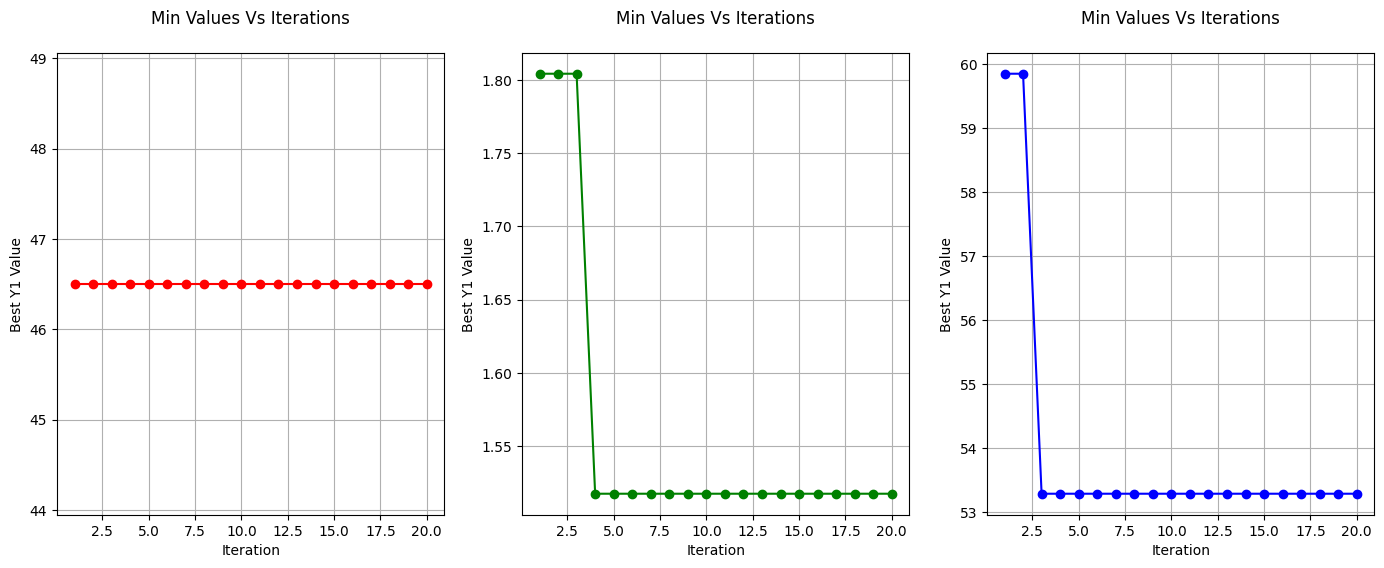

In [21]:
iterations = list(range(1, iteration_number+1))
plt.figure(figsize=(17, 6))
color = ['r','g','b']
for i in range(3):
    plt.subplot(1,3,i+1)
    plt.plot(iterations,best_y_values[:,i] , marker='o', linestyle='-', color=color[i] )
    # plt.plot(iterations,best_y_values[1] , marker='o', linestyle='-', color='r')
    # plt.plot(iterations,best_y_values[2] , marker='o', linestyle='-', color='g')
#plt.errorbar(iterations, np.mean(supra_best,axis=0),yerr=np.std(supra_best,axis=0))
    plt.title('Min Values Vs Iterations\n')
    plt.xlabel('Iteration')
    plt.ylabel('Best Y1 Value')
    plt.grid(True)
plt.show()

    

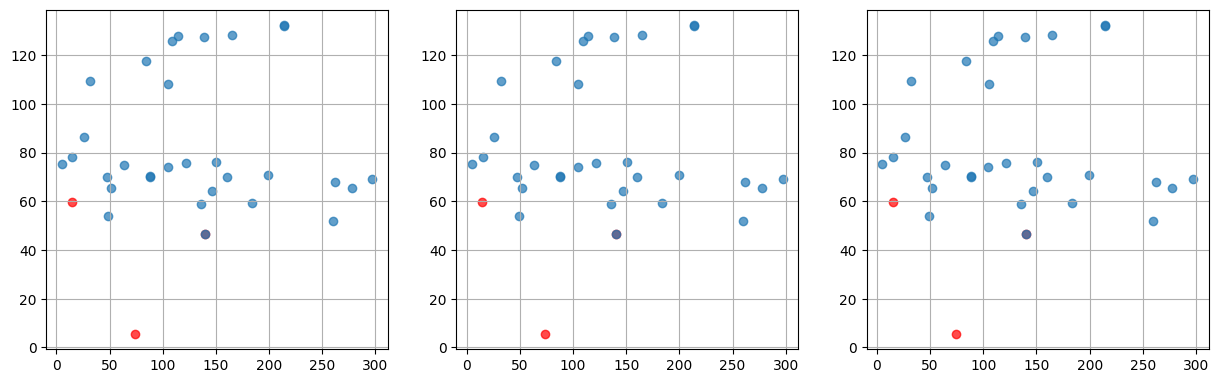

In [22]:
plt.figure(figsize=(15, 15))
#x_vol = sum_constraint(train_x,300)
for i in range(3):
    plt.subplot(3,3,i+1)
    plt.scatter(frame_x[0], frame_y[0], label='original', alpha=0.7,c='r')
    plt.scatter(train_x[len(frame_x[0]):len(train_x),0], train_y[len(frame_x[0]):len(train_x),0], label='Training Data', alpha=0.7)

    #plt.scatter(train_x[:, i].cpu().numpy(), train_y[:, i].cpu().numpy(), color='blue')
    # plt.title('Objective %s '%(i+1)+'vs. Objective %s' %(i+1))
    # plt.xlabel('Objective %s Values'%(j+1))
    # plt.ylabel('Objective  %s Values'%(i+1))
    plt.grid(True)

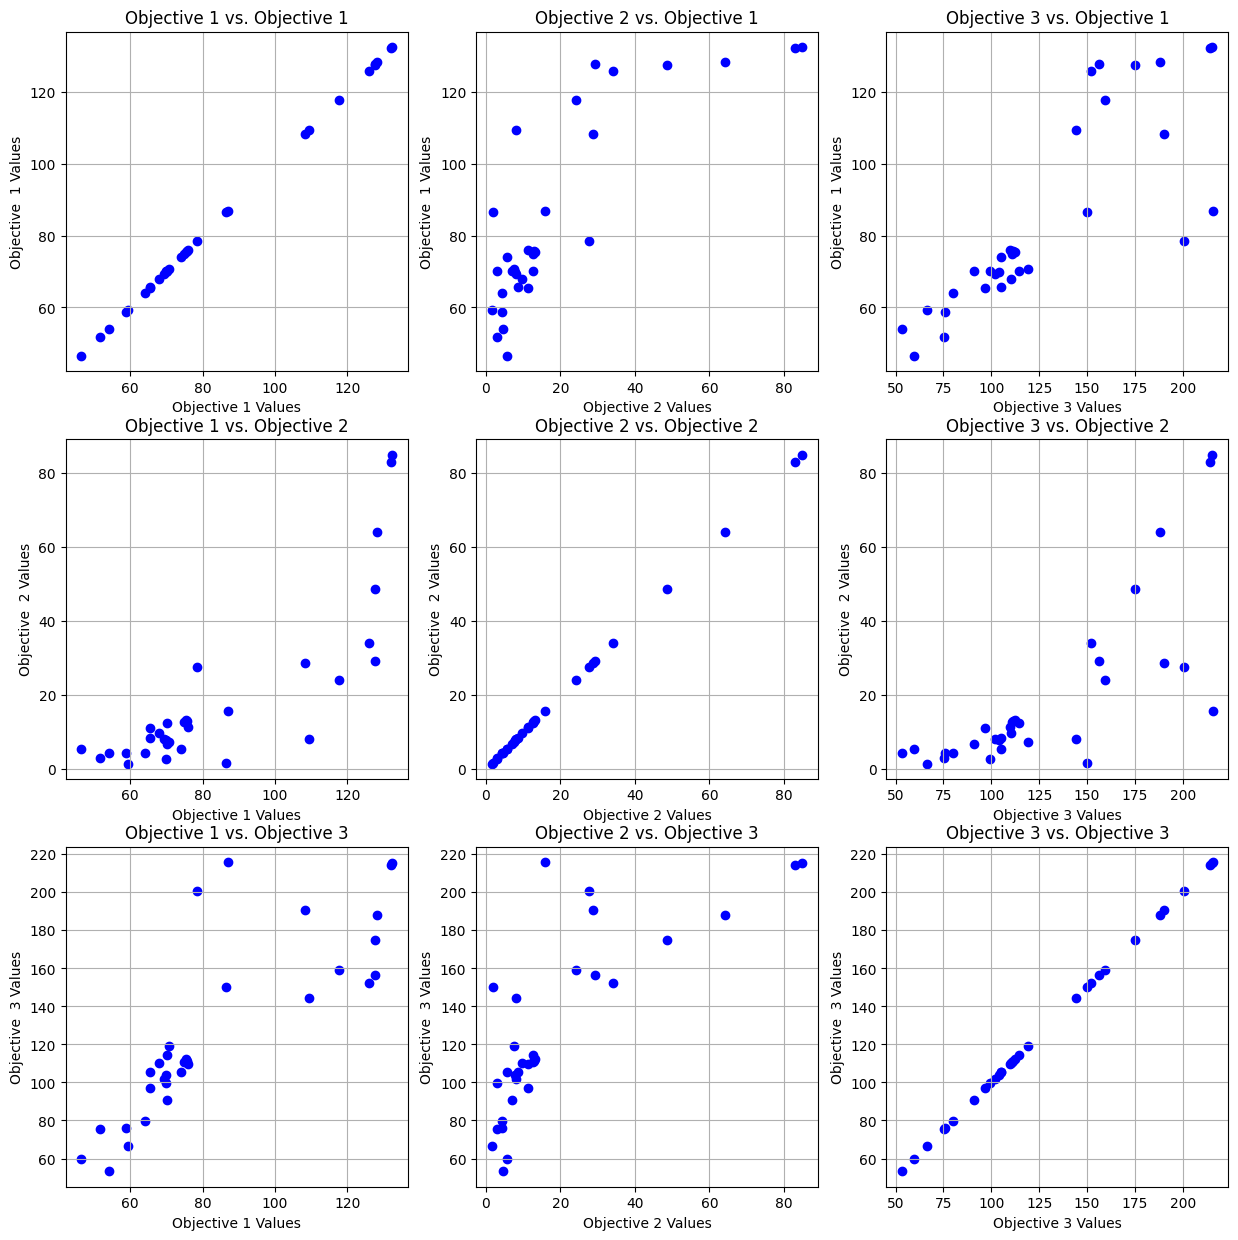

In [23]:
plt.figure(figsize=(15, 15))
n = [0,1,2]
count = 0
for i in n:
    for j in n:
        count +=1
        plt.subplot(3,3,count)
        plt.scatter(train_y[:, j].cpu().numpy(), train_y[:, i].cpu().numpy(), color='blue')
        plt.title('Objective %s '%(j+1)+'vs. Objective %s' %(i+1))
        plt.xlabel('Objective %s Values'%(j+1))
        plt.ylabel('Objective  %s Values'%(i+1))
        plt.grid(True)
plt.show()